# Functional distortion examples

We fit an interleaving with ceREEBerus for each graph pair and recover two maps. The hand-built examples show how to supply the maps yourself.

**Read the plots from left to right.** The top row shows $\Phi\colon F\to G$ and the bottom row shows $\Psi\colon G\to F$. In each row, a color marks a path on the left and its image on the right.

**Read the scores in grid units.** Scores are rounded to three decimal places. Each height error measures the largest vertical shift under one map. $D$ measures how much the maps change height-range distances, and $\mathrm{FD}$ is the maximum of the two height errors and $D$.

## Setup

`Interleave.fit` fits the interleaving, `maps_from_interleave` recovers the maps, and `functional_distortion` evaluates them. Preprocessing includes graph setup and the interleaving search. The saved runs use ceREEBerus 0.2.0, PuLP 3.3.2 with single-threaded CBC, and `PYTHONHASHSEED=0`.

In [1]:
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from cereeberus import Interleave
from cereeberus.data import ex_mappergraphs as ex
from pulp import PULP_CBC_CMD

if Path.cwd().name == "experiments":
    sys.path.insert(0, str(Path.cwd().parent))

from core.distortion import functional_distortion
from core.fd_map_build import maps_from_interleave
from core.functionaldistortiongraph import FunctionalDistortionGraph
from visualize.fd_metromaps import draw_fd_maps, set_integer_ticks


In [2]:


def report(label, F, G, Phi, Psi, preprocessing, construction):
    """Print rounded scores for Phi and Psi and return FD in grid units.

    Preprocessing and construction are elapsed times in seconds.
    """
    start = perf_counter()
    result = functional_distortion(F, G, Phi, Psi)
    evaluation = perf_counter() - start
    total = preprocessing + construction + evaluation
    print(
        f"{label} — Elapsed time: total {total:.3f} s "
        f"(preprocessing: {preprocessing:.3f} s, FD map construction: {construction:.3f} s, "
        f"distortion computation: {evaluation:.3f} s)"
    )
    print(
        f"Height error Φ = {result['height_Phi_units']} | Height error Ψ = {result['height_Psi_units']} | "
        f"D = {result['D_units']} | FD = {result['FD_units']}"
    )
    return result["FD_units"]


def run_example(label, make_pair):
    """Fit the MapperGraph pair returned by make_pair and recover both maps.

    Return the map dictionary and the evaluated FD in grid units.
    """
    start = perf_counter()
    F, G = make_pair()
    interleaving = Interleave(F, G)
    solver = PULP_CBC_CMD(msg=False, threads=1, options=["randomSeed 1", "randomCbcSeed 1"])
    interleaving.fit(pulp_solver=solver)
    preprocessing = perf_counter() - start

    start = perf_counter()
    maps = maps_from_interleave(interleaving, seed=0)
    construction = perf_counter() - start

    fd = report(label, maps["F"], maps["G"], maps["Phi"], maps["Psi"],
                preprocessing, construction)
    return maps, fd


## Identical loops

The maps match the two identical mappers at the same heights, so every fd is zero.

Identical loops — Elapsed time: total 0.337 s (preprocessing: 0.335 s, FD map construction: 0.001 s, distortion computation: 0.001 s)
Height error Φ = 0.0 | Height error Ψ = 0.0 | D = 0.0 | FD = 0.0


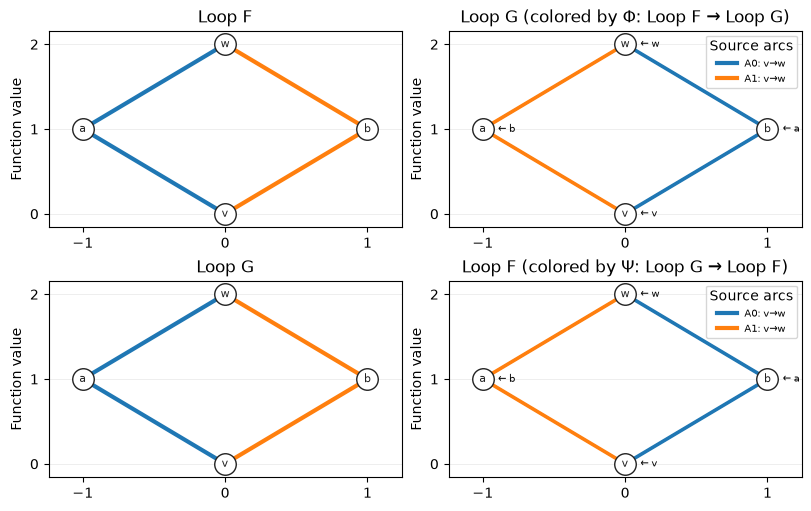

In [3]:
def loop():
    """Return a height-two loop with two arms from v to w."""
    return FunctionalDistortionGraph.from_edges(
        {"v": 0, "a": 1, "b": 1, "w": 2},
        [("v", "a"), ("v", "b"), ("a", "w"), ("b", "w")],
    )



loop_pos = {"v": (0, 0), "a": (-1, 1), "b": (1, 1), "w": (0, 2)}

maps, _ = run_example("Identical loops", lambda: (loop().mapper, loop().mapper))
draw_fd_maps(maps["Phi"], maps["Psi"], posF=loop_pos, posG=loop_pos,
             names=("Loop F", "Loop G"), figsize=(8, 5))
plt.show()


## Line and loop

Both graphs span heights $0$ to $2$. The map from the line follows one arm of the loop. The other map sends both arms to the line at the same height.

Line and loop — Elapsed time: total 0.098 s (preprocessing: 0.089 s, FD map construction: 0.008 s, distortion computation: 0.002 s)
Height error Φ = 0.0 | Height error Ψ = 0.0 | D = 0.5 | FD = 0.5


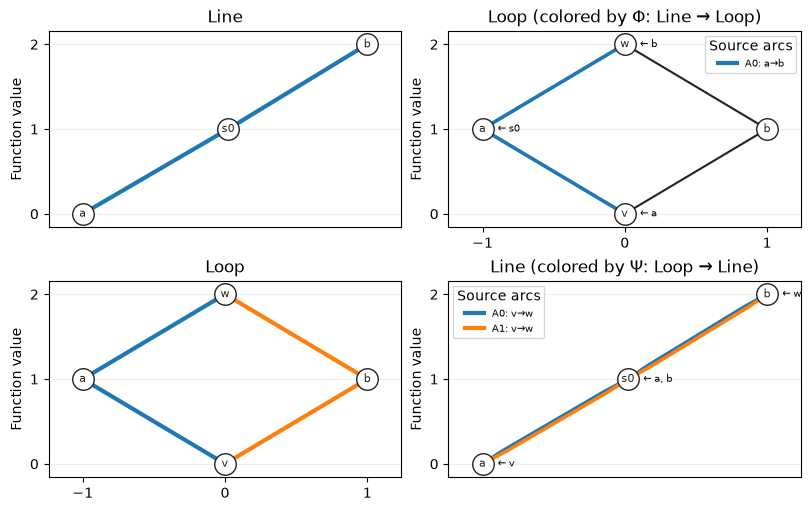

In [4]:
maps, _ = run_example("Line and loop", lambda: (ex.line(0, 2, seed=0), loop().mapper))
draw_fd_maps(maps["Phi"], maps["Psi"], posG=loop_pos, names=("Line", "Loop"), figsize=(8, 5))
plt.show()


## Loop and edge (different heights)

The loop reaches height $2$ and the edge reaches height $1$. The maximum height difference determines FD for the recovered maps.

Loop and edge — Elapsed time: total 0.056 s (preprocessing: 0.047 s, FD map construction: 0.006 s, distortion computation: 0.003 s)
Height error Φ = 1.0 | Height error Ψ = 0.0 | D = 0.5 | FD = 1.0


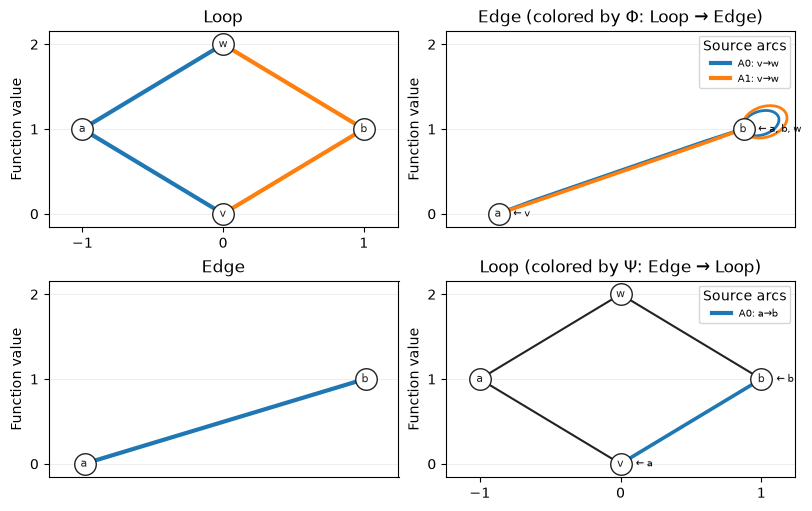

In [5]:
maps, _ = run_example("Loop and edge", lambda: (loop().mapper, ex.line(0, 1, seed=0)))
draw_fd_maps(maps["Phi"], maps["Psi"], posF=loop_pos, names=("Loop", "Edge"), figsize=(8, 5))
plt.show()


## Y and inverted Y from an interleaving

The recovered maps detour across a fork in each direction. 

Y and inverted Y — Elapsed time: total 0.159 s (preprocessing: 0.109 s, FD map construction: 0.013 s, distortion computation: 0.037 s)
Height error Φ = 1.0 | Height error Ψ = 1.0 | D = 1.0 | FD = 1.0


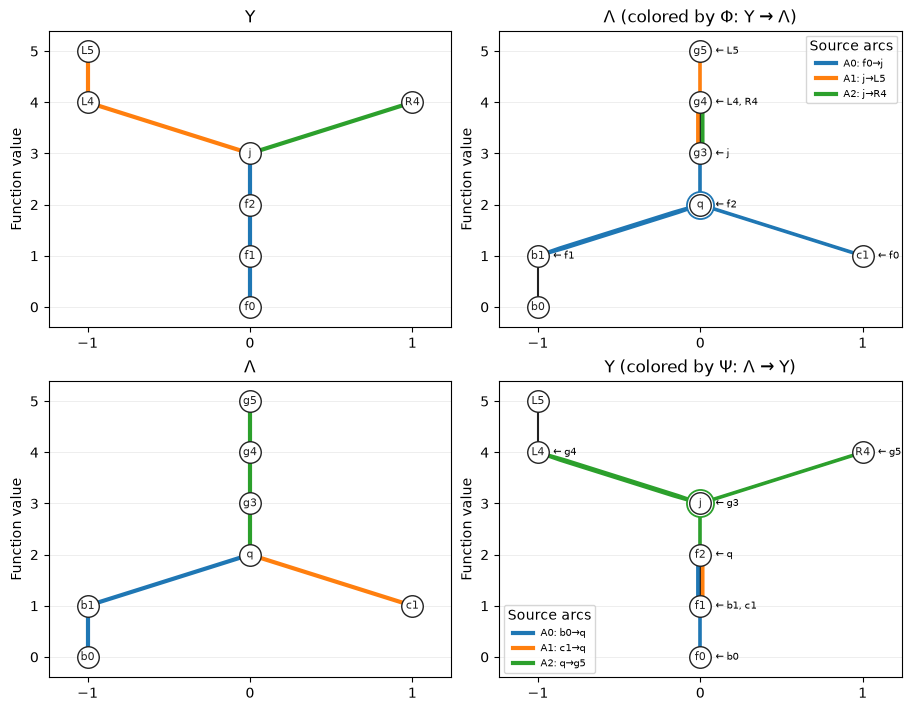

In [6]:
def y_pair():
    """Return a Y and an inverted Y with the same height range."""
    F = FunctionalDistortionGraph.from_edges(
        {"f0": 0, "f1": 1, "f2": 2, "j": 3, "L4": 4, "L5": 5, "R4": 4},
        [("f0", "f1"), ("f1", "f2"), ("f2", "j"), ("j", "L4"), ("L4", "L5"), ("j", "R4")],
    )
    G = FunctionalDistortionGraph.from_edges(
        {"g5": 5, "g4": 4, "g3": 3, "q": 2, "b1": 1, "b0": 0, "c1": 1},
        [("g5", "g4"), ("g4", "g3"), ("g3", "q"), ("q", "b1"), ("b1", "b0"), ("q", "c1")],
    )
    return F, G


y_maps, _ = run_example("Y and inverted Y", lambda: tuple(graph.mapper for graph in y_pair()))
x_f = {"L4": -1, "L5": -1, "R4": 1}
x_g = {"b0": -1, "b1": -1, "c1": 1}
pos_f = {v: (x_f.get(v, 0), h) for v, h in y_maps["F"].f.items()}
pos_g = {v: (x_g.get(v, 0), h) for v, h in y_maps["G"].f.items()}
draw_fd_maps(y_maps["Phi"], y_maps["Psi"], posF=pos_f, posG=pos_g, names=("Y", "Λ"),
             show_frechet_param=False, figsize=(9, 7))
plt.show()


## Hand-built maps

`map_to` constructs each map from the specified vertex images.

### Loop and edge

The choice of vertex images changes $D$ from $1/2$ to $3/4$. The maximum height error still determines FD.

Loop → edge (hand-built) — Elapsed time: total 0.004 s (preprocessing: 0.001 s, FD map construction: 0.000 s, distortion computation: 0.003 s)
Height error Φ = 1.0 | Height error Ψ = 0.0 | D = 0.75 | FD = 1.0


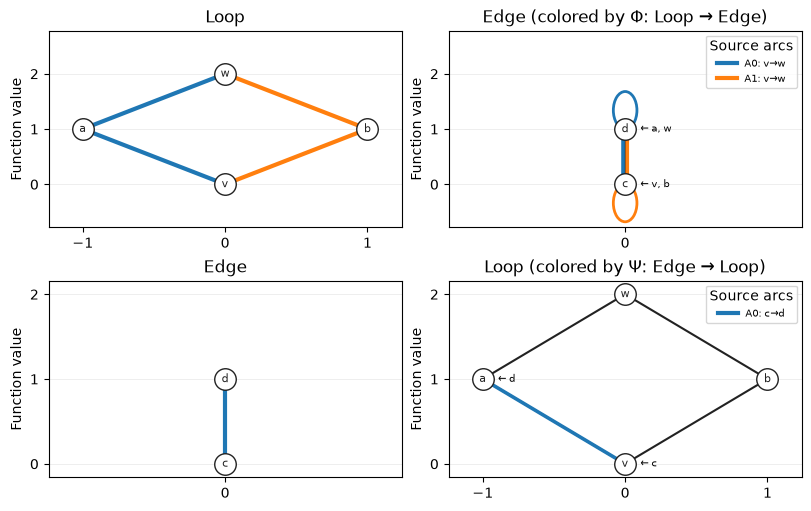

In [7]:
start = perf_counter()
F = loop()
G = FunctionalDistortionGraph.from_edges({"c": 0, "d": 1}, [("c", "d")])
preprocessing = perf_counter() - start

start = perf_counter()
Phi = F.map_to(G, {"v": "c", "a": "d", "b": "c", "w": "d"})
Psi = G.map_to(F, {"c": "v", "d": "a"})
construction = perf_counter() - start
report("Loop → edge (hand-built)", F, G, Phi, Psi, preprocessing, construction)

draw_fd_maps(Phi, Psi, posF=loop_pos, posG={"c": (0, 0), "d": (0, 1)},
             names=("Loop", "Edge"), figsize=(8, 5))
plt.show()


### Y and inverted Y

These maps preserve height by sending each shorter branch to the longer branch at the same height. FD is determined by $D$.

Y → Λ (hand-built) — Elapsed time: total 0.005 s (preprocessing: 0.002 s, FD map construction: 0.000 s, distortion computation: 0.003 s)
Height error Φ = 0.0 | Height error Ψ = 0.0 | D = 0.5 | FD = 0.5


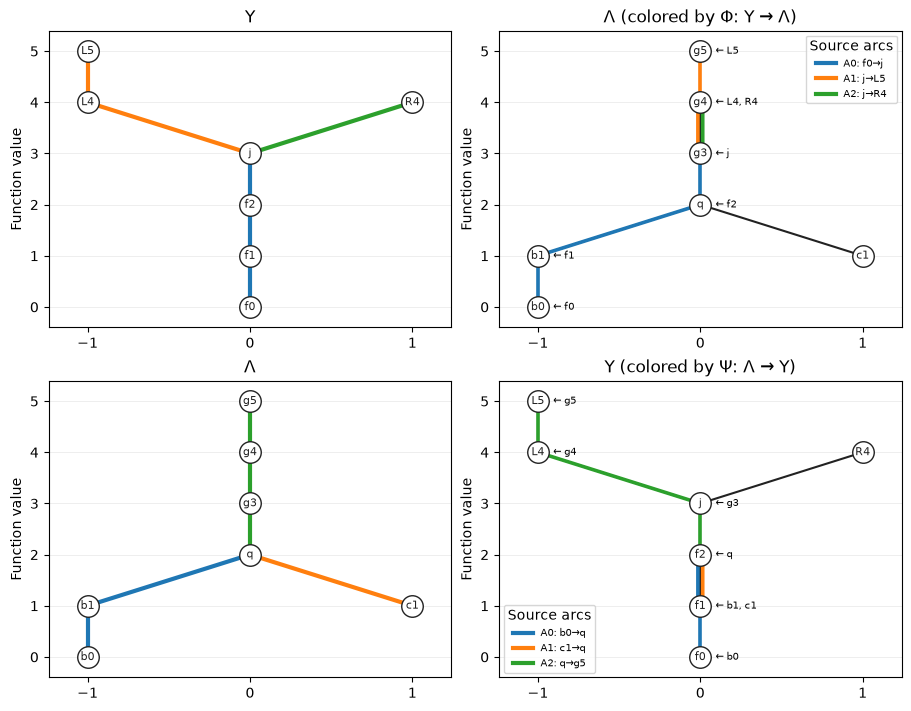

In [8]:
start = perf_counter()
F, G = y_pair()
preprocessing = perf_counter() - start

start = perf_counter()
Phi = F.map_to(G, {"f0": "b0", "f1": "b1", "f2": "q", "j": "g3",
                  "L4": "g4", "L5": "g5", "R4": "g4"})
Psi = G.map_to(F, {"b0": "f0", "b1": "f1", "q": "f2", "g3": "j",
                  "g4": "L4", "g5": "L5", "c1": "f1"})
construction = perf_counter() - start
_ = report("Y → Λ (hand-built)", F, G, Phi, Psi, preprocessing, construction)


draw_fd_maps(Phi, Psi, posF=pos_f, posG=pos_g, names=("Y", "Λ"), figsize=(9, 7))
plt.show()


The height-preserving Y maps attain $d_{FD}=1/2$. With height error below $1/2$, the short tip and a point on the longer branch must share an image on the unique upper branch of $G$. Their path passes through the fork at height $3$, so their height-range distance is at least $1$.

## Torus–line family

The loop spans heights $1$ through $h+1$, with one stem edge at each end. We compare the computed FD with the exact distance $d_{FD}=h/4$. For odd $h$, the midpoint of the loop arms lies inside an edge.

The plot compares scores across loop heights. The map drawing below it shows the pair for $h=3$.

Torus h=2 — Elapsed time: total 0.113 s (preprocessing: 0.100 s, FD map construction: 0.010 s, distortion computation: 0.003 s)
Height error Φ = 0.0 | Height error Ψ = 0.0 | D = 0.5 | FD = 0.5
Torus h=3 — Elapsed time: total 0.128 s (preprocessing: 0.111 s, FD map construction: 0.013 s, distortion computation: 0.004 s)
Height error Φ = 0.0 | Height error Ψ = 0.0 | D = 0.75 | FD = 0.75
Torus h=4 — Elapsed time: total 0.145 s (preprocessing: 0.125 s, FD map construction: 0.015 s, distortion computation: 0.005 s)
Height error Φ = 0.0 | Height error Ψ = 0.0 | D = 1.0 | FD = 1.0
Torus h=5 — Elapsed time: total 0.307 s (preprocessing: 0.271 s, FD map construction: 0.029 s, distortion computation: 0.007 s)
Height error Φ = 0.0 | Height error Ψ = 0.0 | D = 1.25 | FD = 1.25
Torus h=7 — Elapsed time: total 0.379 s (preprocessing: 0.336 s, FD map construction: 0.033 s, distortion computation: 0.011 s)
Height error Φ = 0.0 | Height error Ψ = 0.0 | D = 1.75 | FD = 1.75
Torus h=8 — Elapsed time: tot

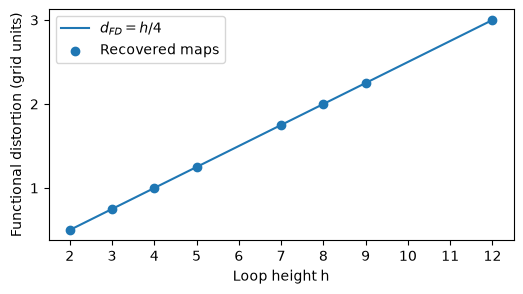

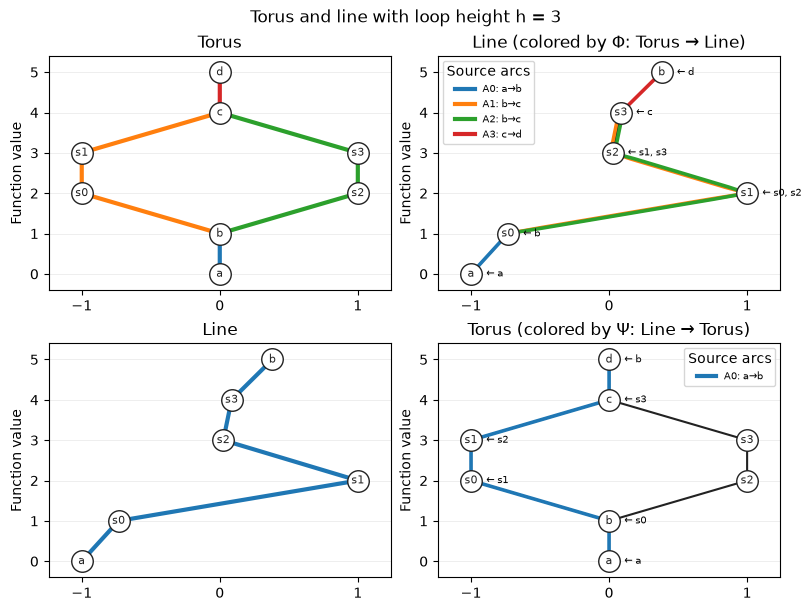

In [9]:
heights = (2, 3, 4, 5, 7, 8, 9, 12)
scores = []
for h in heights:
    maps, fd = run_example(
        f"Torus h={h}",
        lambda: (ex.torus(0, 1, h + 1, h + 2, delta=1, seed=0),
                 ex.line(0, h + 2, seed=0)),
    )
    scores.append(float(fd))
    if h == 3:
        torus_maps = maps

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(heights, [h / 4 for h in heights], label=r"$d_{FD}=h/4$")
ax.scatter(heights, scores, label="Recovered maps", zorder=3)
ax.set(xlabel="Loop height h", ylabel="Functional distortion (grid units)")
set_integer_ticks(ax)
ax.legend()
plt.show()

fig = draw_fd_maps(torus_maps["Phi"], torus_maps["Psi"], names=("Torus", "Line"), figsize=(8, 6))
fig.suptitle("Torus and line with loop height h = 3")
plt.show()


## A/B pair from ceREEBerus

The colors show the images of source arcs in each direction.

A/B — Elapsed time: total 3.750 s (preprocessing: 2.110 s, FD map construction: 0.345 s, distortion computation: 1.295 s)
Height error Φ = 4.0 | Height error Ψ = 2.0 | D = 3.5 | FD = 4.0


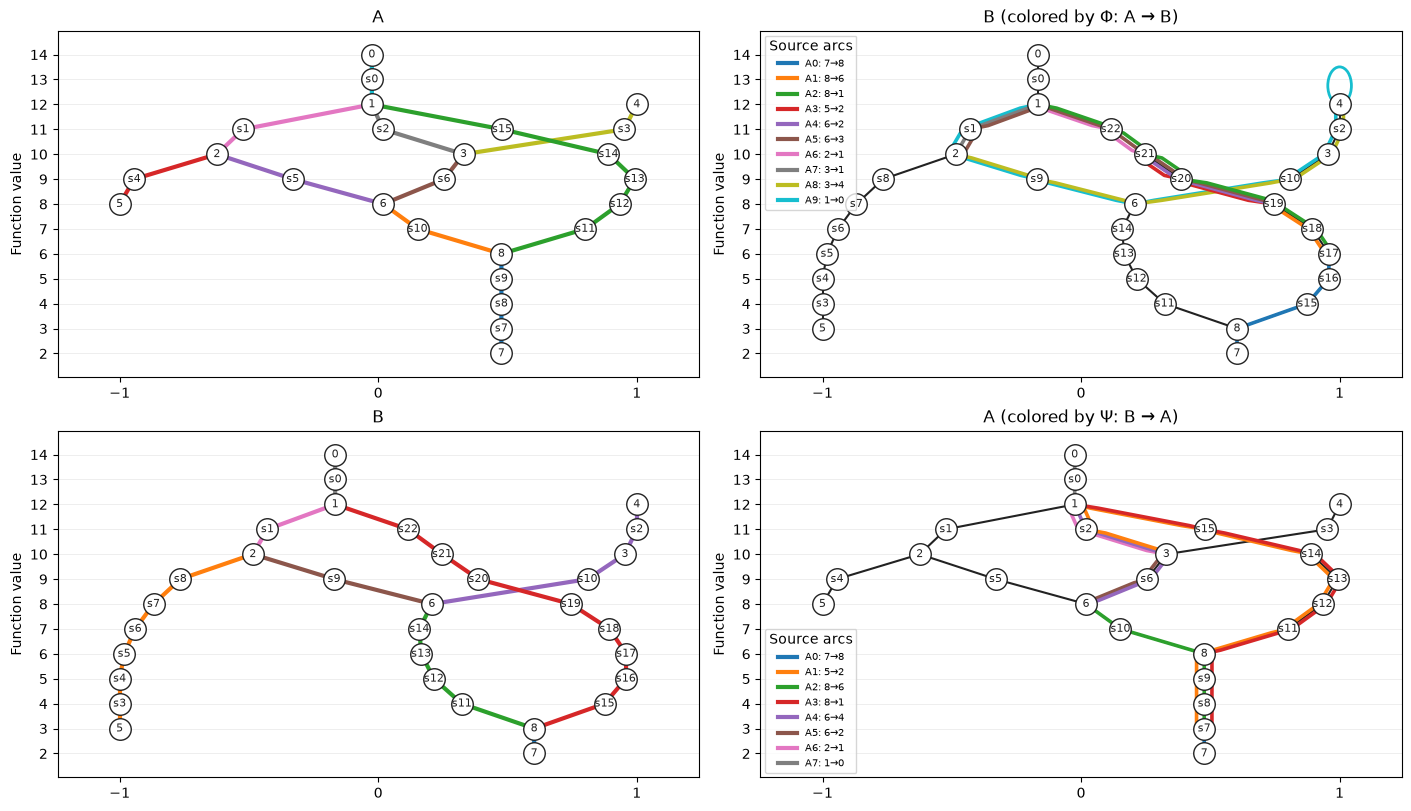

In [10]:
maps, _ = run_example(
    "A/B", lambda: (ex.interleave_example_A(seed=0), ex.interleave_example_B(seed=0))
)
draw_fd_maps(maps["Phi"], maps["Psi"], names=("A", "B"), figsize=(14, 8), show_breakpoints=False,
             show_vertmaps=False)
plt.show()
